# M4: text–face agreement (Gate 3)

Plots of `results/m4/` as written by `scripts/m4_agreement.py`: the gate metrics against their nulls, the per-take face readout against the story labels, story-level versus within-story agreement, the lag search, and example traces. Reading condition only.

Regenerate the inputs with `.venv/bin/python scripts/m4_agreement.py --lag-grid=-1:2:0.25`, then run all cells. Figures are saved to `results/m4/figures/`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyarrow.parquet as pq

ROOT = Path.cwd() if (Path.cwd() / "results" / "m4").exists() else Path.cwd().parent
M4 = ROOT / "results" / "m4"
FIG = M4 / "figures"
FIG.mkdir(parents=True, exist_ok=True)

metrics = json.loads((M4 / "agreement_metrics.json").read_text())
split = json.loads((M4 / "split.json").read_text())
seg_table = pq.read_table(M4 / "segments.parquet")
seg = {c: seg_table[c].to_numpy(zero_copy_only=False) for c in seg_table.column_names}
stories = {r["id"]: r for r in map(json.loads, (ROOT / "data/stories/stories.jsonl").read_text().splitlines()) if r}
COND = "read"

# Palette (the dataviz reference instance): categorical slots in fixed order; a cool/warm pair for polarity.
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100", "magenta": "#e87ba4",
     "green": "#008300", "violet": "#6250d6", "red": "#e34948", "gray": "#9a9a96", "ink": "#0b0b0b", "ink2": "#52514e"}
POS_COL, NEG_COL, NEU_COL = C["blue"], C["orange"], C["gray"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.edgecolor": "#c3c2b7", "axes.titleweight": "bold",
                     "axes.titlesize": 11, "axes.labelsize": 10, "font.size": 10, "legend.frameon": False})

POS = {"Exuberant Joy", "Compassionate Gratitude", "Peaceful Contentment", "Playful Amusement", "Competitive Pride"}
NEG = {"Despair and Shame", "Hostile Anger", "Fear and Overwhelm", "Depleted Disengagement", "Vigilant Suspicion"}

def polarity(story_id):
    """+1 / -1 for single-emotion stories by cluster, 0 for neutral, None for mixed (turn) stories."""
    st = stories[story_id]
    if st.get("kind") == "neutral":
        return 0
    cl = st.get("clusters", [])
    if st.get("kind") != "single" or len(cl) != 1:
        return None
    return 1 if cl[0] in POS else -1 if cl[0] in NEG else None

def pol_color(p):
    return POS_COL if p == 1 else NEG_COL if p == -1 else NEU_COL

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")

read = seg["condition"] == COND
held = seg["split"] == "heldout" if "split" in seg else np.isin(seg["story"], split["holdout_stories"]) | (seg["session"] == split["holdout_session"])
ok = np.isfinite(seg["face_valence_z"]) & np.isfinite(seg["text_valence_z"])
H = metrics["results"]["heldout"][COND]
print(metrics["dataset"]["n_segments"], "segments;", metrics["dataset"]["heldout_segments"], "held-out;",
      "held-out session", split["holdout_session"], "+", len(split["holdout_stories"]), "held-out stories;",
      "lag", metrics["lag"]["lag"], "s")

170 segments; 123 held-out; held-out session 20261109-2316 + 15 held-out stories; lag -0.25 s


## 1. Gate 3 at a glance

Each held-out metric against its story-level permutation null (mean ± 2 SD of 1000 permutations). A dot to the right of its band is a result; inside it is noise. Three variants: the zero-training readout, the ridge map fitted on development segments, and the blendshape baseline.

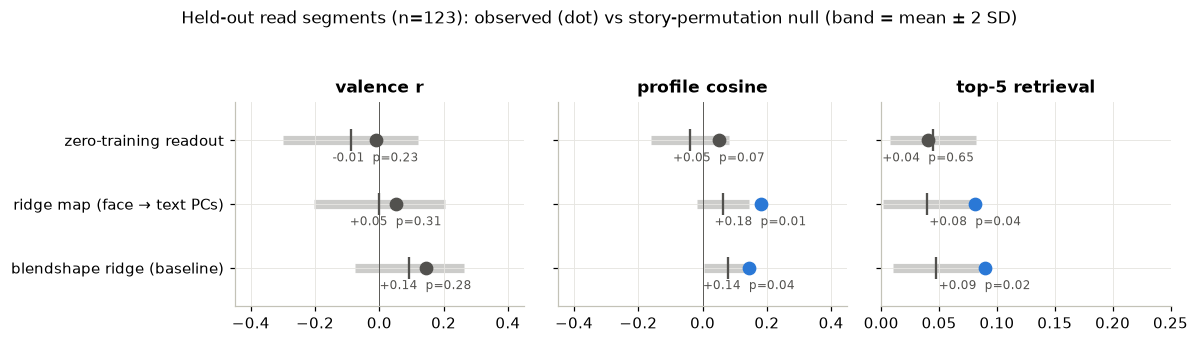

Gate 3 valence: no (r -0.01, p 0.23); turns: no


In [2]:
variants = [("zero_training", "zero-training readout"), ("ridge", "ridge map (face → text PCs)"), ("blendshapes", "blendshape ridge (baseline)")]
stats = [("valence_r", "valence r"), ("cosine", "profile cosine"), ("top5", "top-5 retrieval")]
fig, axes = plt.subplots(1, 3, figsize=(11, 2.9), sharey=True)
for ax, (key, label) in zip(axes, stats):
    for i, (vk, vlabel) in enumerate(variants):
        R = H.get(vk)
        if not R or "p" not in R:
            continue
        obs = R["retrieval"]["top5"] if key == "top5" else R[key]
        mu, sd = R["null_mean"][f"{key}_story"], R["null_sd"][f"{key}_story"]
        p = R["p"][f"{key}_story"]
        ax.plot([mu - 2 * sd, mu + 2 * sd], [i, i], color=C["gray"], lw=6, solid_capstyle="butt", alpha=0.5, zorder=1)
        ax.plot(mu, i, "|", color=C["ink2"], ms=14, mew=1.5, zorder=2)
        ax.plot(obs, i, "o", color=C["blue"] if p < 0.05 else C["ink2"], ms=8, zorder=3)
        ax.annotate(f"{obs:+.2f}  p={p:.2f}", (obs, i), xytext=(0, -14), textcoords="offset points",
                    ha="center", fontsize=8, color=C["ink2"])
    ax.set_yticks(range(len(variants))); ax.set_yticklabels([v[1] for v in variants]); ax.invert_yaxis()
    ax.set_ylim(len(variants) - 0.4, -0.6)
    ax.set_title(label); ax.axvline(0, color=C["ink2"], lw=0.6)
axes[0].set_xlim(-0.45, 0.45); axes[1].set_xlim(-0.45, 0.45); axes[2].set_xlim(0, 0.25)
fig.suptitle(f"Held-out {COND} segments (n={H['zero_training']['n_segments']}): observed (dot) vs story-permutation null (band = mean ± 2 SD)",
             y=1.06, fontsize=11)
fig.tight_layout()
save(fig, "01_gate_vs_null"); plt.show()
g = metrics["gate3"]
print("Gate 3 valence:", "pass" if g["valence"]["pass"] else "no", f"(r {g['valence']['r']:+.2f}, p {g['valence']['p_story']:.2f});",
      "turns:", "pass" if g["turn"]["pass"] else "no")

## 2. The face readout per take, against the story label

Mean face valence over each reading take (z-scored on development data), one bar per take, sorted. Bars are colored by the story's labelled polarity (cluster), not by the model: positive stories should sit on the right, negative on the left. The small marker is the text side's story mean on the same z scale.

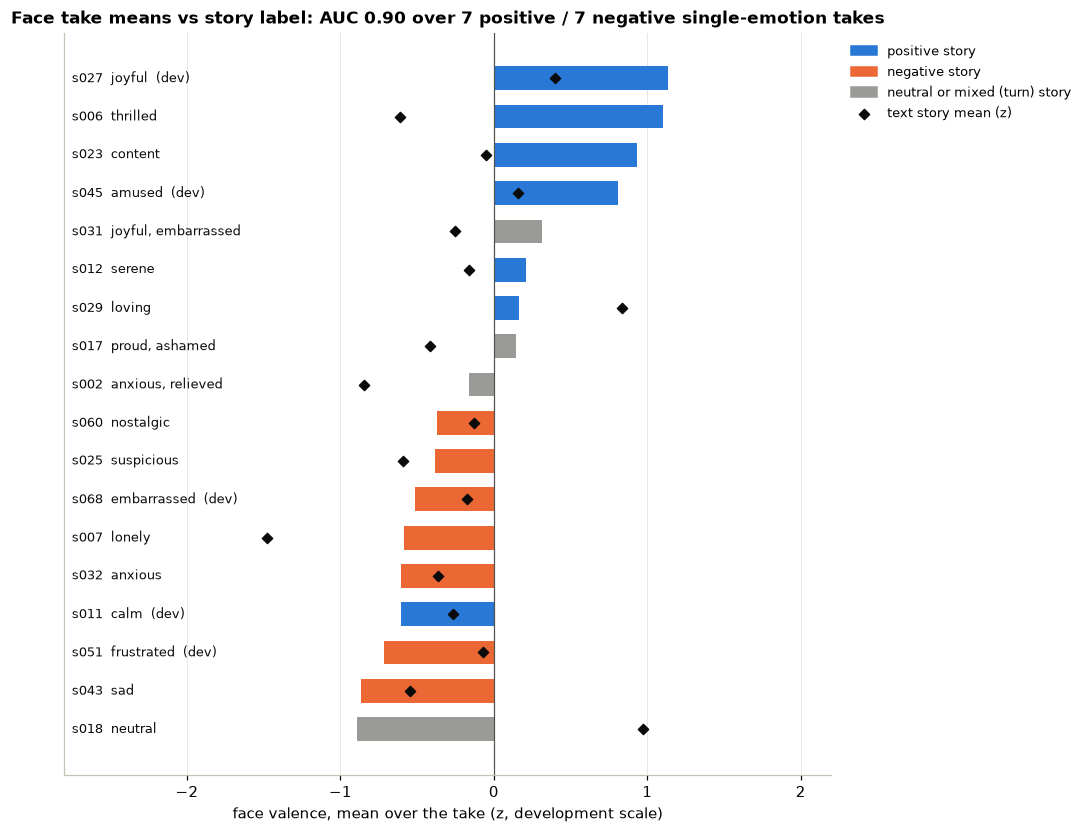

In [3]:
rows = []
for (sess, take, story) in sorted({(s, t, st) for s, t, st in zip(seg["session"], seg["take"], seg["story"]) if True}):
    m = read & ok & (seg["take"] == take) & (seg["session"] == sess)
    if not m.any():
        continue
    rows.append({"session": sess, "take": take, "story": story, "face": seg["face_valence_z"][m].mean(),
                 "text": seg["text_valence_z"][m].mean(), "pol": polarity(story), "held": bool(held[m].all()),
                 "label": ", ".join(stories[story].get("emotions") or ["neutral"]), "kind": stories[story].get("kind")})
rows.sort(key=lambda r: r["face"])
fig, ax = plt.subplots(figsize=(9, 0.42 * len(rows) + 1.2))
y = np.arange(len(rows))
ax.barh(y, [r["face"] for r in rows], color=[pol_color(r["pol"]) for r in rows], height=0.62, zorder=2)
ax.scatter([r["text"] for r in rows], y, marker="D", s=22, color=C["ink"], zorder=3, label="text story mean (z)")
for yi, r in zip(y, rows):
    ax.text(-2.75, yi, f"{r['story']}  {r['label']}" + ("" if r["held"] else "  (dev)"), va="center", ha="left", fontsize=8.5, color=C["ink"])
ax.set_yticks([]); ax.set_xlim(-2.8, 2.2); ax.axvline(0, color=C["ink2"], lw=0.8)
ax.set_xlabel("face valence, mean over the take (z, development scale)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=POS_COL, label="positive story"), Patch(color=NEG_COL, label="negative story"),
                   Patch(color=NEU_COL, label="neutral or mixed (turn) story"), ax.collections[0]],
          loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=8.5)
single = [r for r in rows if r["pol"] in (1, -1)]
from cogmirror import metrics as M
auc = M.auc(np.array([r["face"] for r in single if r["pol"] == 1]), np.array([r["face"] for r in single if r["pol"] == -1]))
ax.set_title(f"Face take means vs story label: AUC {auc:.2f} over {sum(r['pol']==1 for r in single)} positive / {sum(r['pol']==-1 for r in single)} negative single-emotion takes")
save(fig, "02_take_means_vs_label"); plt.show()

## 3. Story level versus within story

Left: one point per take, text story mean against face take mean. Right: the same segments after subtracting each story's mean from both sides, i.e. the sentence-to-sentence agreement Gate 3 scores. The gate's null is at the story level, so these two panels separate "tracks which story" from "tracks which sentence".

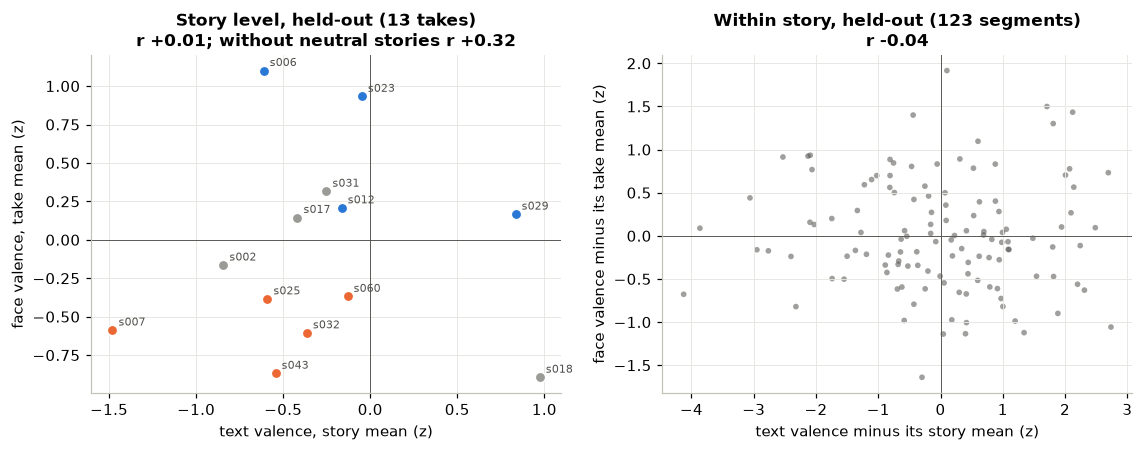

In [4]:
def story_and_within(mask):
    m = mask & ok
    f, x, key = seg["face_valence_z"][m], seg["text_valence_z"][m], np.char.add(seg["session"][m], seg["take"][m])
    units = np.unique(key)
    fm = {u: f[key == u].mean() for u in units}; xm = {u: x[key == u].mean() for u in units}
    fw = f - np.array([fm[u] for u in key]); xw = x - np.array([xm[u] for u in key])
    return (np.array([fm[u] for u in units]), np.array([xm[u] for u in units]), units), (fw, xw, key)

(F, X, units), (fw, xw, key) = story_and_within(read & held)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
ax = axes[0]
for u, f, x in zip(units, F, X):
    story = seg["story"][np.char.add(seg["session"], seg["take"]) == u][0]
    ax.scatter(x, f, s=46, color=pol_color(polarity(story)), edgecolor="white", lw=1, zorder=3)
    ax.annotate(story, (x, f), xytext=(4, 3), textcoords="offset points", fontsize=7.5, color=C["ink2"])
r_story = np.corrcoef(X, F)[0, 1]
nn = np.array([polarity(seg["story"][np.char.add(seg["session"], seg["take"]) == u][0]) != 0 for u in units])
r_nn = np.corrcoef(X[nn], F[nn])[0, 1]
ax.set_title(f"Story level, held-out ({len(F)} takes)\nr {r_story:+.2f}; without neutral stories r {r_nn:+.2f}")
ax.set_xlabel("text valence, story mean (z)"); ax.set_ylabel("face valence, take mean (z)")
ax.axhline(0, color=C["ink2"], lw=0.6); ax.axvline(0, color=C["ink2"], lw=0.6)
ax = axes[1]
ax.scatter(xw, fw, s=14, color=C["ink2"], alpha=0.55, edgecolor="none")
r_within = np.corrcoef(xw, fw)[0, 1]
ax.set_title(f"Within story, held-out ({len(fw)} segments)\nr {r_within:+.2f}")
ax.set_xlabel("text valence minus its story mean (z)"); ax.set_ylabel("face valence minus its take mean (z)")
ax.axhline(0, color=C["ink2"], lw=0.6); ax.axvline(0, color=C["ink2"], lw=0.6)
fig.tight_layout(); save(fig, "03_story_vs_within"); plt.show()

## 4. Where the variance is

Share of each modality's valence variance that lies between stories (take means) rather than within them. A text signal that is mostly within-story variation at the sentence level has little to agree with unless the face follows sentence by sentence.

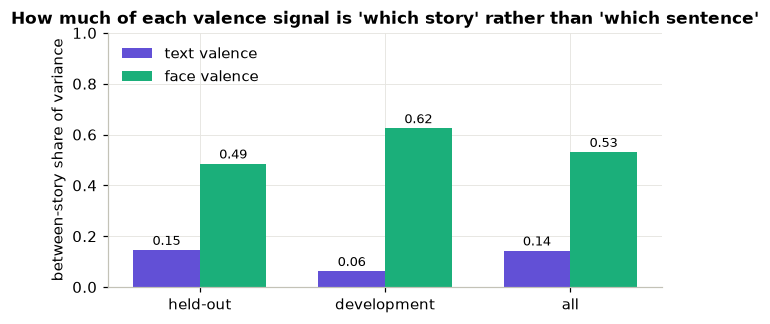

In [5]:
def between_share(mask, col):
    m = mask & ok
    v, key = seg[col][m], np.char.add(seg["session"][m], seg["take"][m])
    means = {u: v[key == u].mean() for u in np.unique(key)}
    return np.var(np.array([means[u] for u in key])) / np.var(v)

subsets = [("held-out", read & held), ("development", read & ~held), ("all", read)]
fig, ax = plt.subplots(figsize=(6.5, 3))
w = 0.36; xs = np.arange(len(subsets))
tb = [between_share(m, "text_valence_z") for _, m in subsets]; fb = [between_share(m, "face_valence_z") for _, m in subsets]
ax.bar(xs - w / 2, tb, w, color=C["violet"], label="text valence", zorder=2)
ax.bar(xs + w / 2, fb, w, color=C["aqua"], label="face valence", zorder=2)
for x, t, f in zip(xs, tb, fb):
    ax.text(x - w / 2, t + 0.02, f"{t:.2f}", ha="center", fontsize=8.5); ax.text(x + w / 2, f + 0.02, f"{f:.2f}", ha="center", fontsize=8.5)
ax.set_xticks(xs); ax.set_xticklabels([s for s, _ in subsets]); ax.set_ylim(0, 1); ax.set_ylabel("between-story share of variance")
ax.set_title("How much of each valence signal is 'which story' rather than 'which sentence'"); ax.legend(loc="upper left")
save(fig, "04_variance_shares"); plt.show()

## 5. Lag search

Development-data valence correlation as a function of the face–text lag (positive: the face trails the text). A flat curve means the lag is not identifiable from this much data; the analysis then uses the plateau's center.

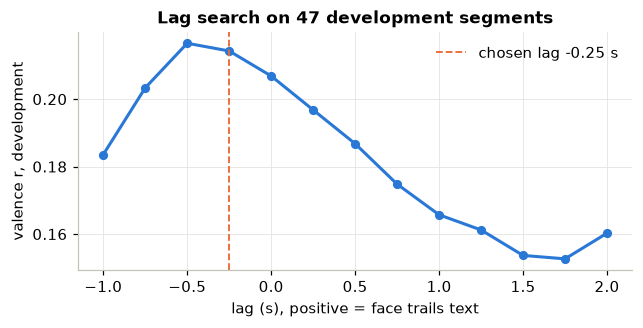

In [6]:
lag = metrics["lag"]
curve = lag["per_condition"].get(COND, lag)["curve"]
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.plot([c["lag"] for c in curve], [c["r"] for c in curve], "-o", color=C["blue"], lw=2, ms=5)
ax.axvline(lag["lag"], color=C["orange"], lw=1.2, ls="--", label=f"chosen lag {lag['lag']:+.2f} s")
ax.set_xlabel("lag (s), positive = face trails text"); ax.set_ylabel("valence r, development"); ax.legend()
ax.set_title(f"Lag search on {curve[0]['n']} development segments")
save(fig, "05_lag_curve"); plt.show()

## 6. Example traces

Face valence over time for held-out takes (the windowed series, standardized within the take) with the text's sentence valence as steps (also standardized within the take). Chosen: the takes with the best and the worst story-level agreement, plus a neutral story if one was recorded.

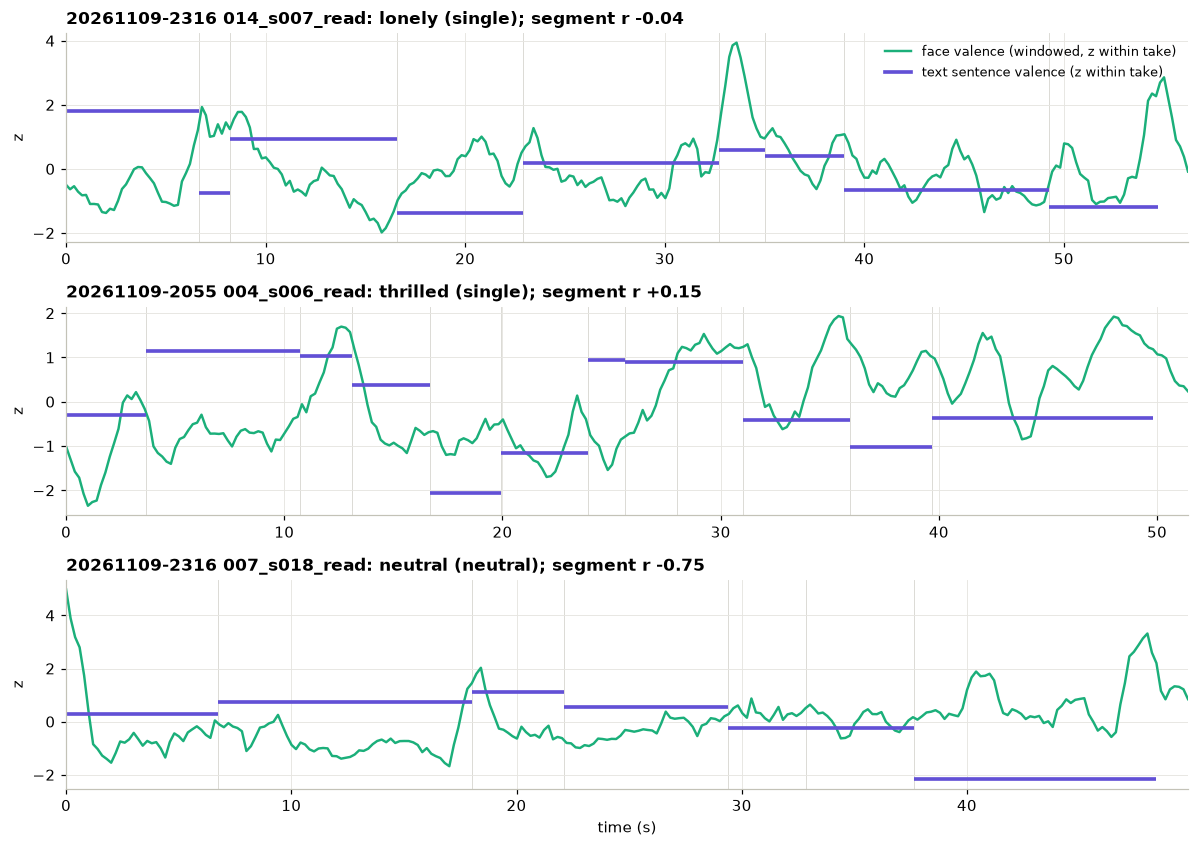

In [7]:
from cogmirror import align, store

def take_series(session, take):
    p = ROOT / "data" / "video" / session / take / f"{take}.parquet"
    cols, _ = store.read_parquet(p)
    return cols

def plot_take(ax, session, take, story):
    cols = take_series(session, take)
    t, v = cols["t"], cols["valence"]
    okv = np.isfinite(v)
    vz = (v - np.nanmean(v)) / (np.nanstd(v) + 1e-9)
    ax.plot(t[okv], vz[okv], color=C["aqua"], lw=1.6, label="face valence (windowed, z within take)")
    m = read & (seg["session"] == session) & (seg["take"] == take)
    tx = seg["text_valence_z"][m]; tz = (tx - tx.mean()) / (tx.std() + 1e-9)
    for s, e, z in zip(seg["start"][m], seg["end"][m], tz):
        ax.plot([s, e], [z, z], color=C["violet"], lw=2.4, solid_capstyle="butt")
        ax.axvline(s, color="#d9d8d3", lw=0.6, zorder=0)
    ax.plot([], [], color=C["violet"], lw=2.4, label="text sentence valence (z within take)")
    st = stories[story]
    r = np.corrcoef(seg["face_valence_z"][m], seg["text_valence_z"][m])[0, 1] if m.sum() > 2 else float("nan")
    ax.set_title(f"{session} {take}: {', '.join(st.get('emotions') or ['neutral'])} ({st.get('kind')}); segment r {r:+.2f}", loc="left")
    ax.set_ylabel("z"); ax.set_xlim(0, float(t.max()))

# pick takes by story-level agreement (held-out, reading)
(F, X, units), _ = story_and_within(read & held)
story_of = {u: seg["story"][np.char.add(seg["session"], seg["take"]) == u][0] for u in units}
agree = {u: f * x for u, f, x in zip(units, F, X) if polarity(story_of[u]) != 0}
neutral = [u for u in units if polarity(story_of[u]) == 0]
picks = [max(agree, key=agree.get), min(agree, key=agree.get)] + neutral[:1]
picks = list(dict.fromkeys(picks))   # unique, in order: best, worst, neutral
fig, axes = plt.subplots(len(picks), 1, figsize=(11, 2.6 * len(picks)), sharex=False)
for ax, u in zip(np.atleast_1d(axes), picks):
    i = np.nonzero(np.char.add(seg["session"], seg["take"]) == u)[0][0]
    plot_take(ax, seg["session"][i], seg["take"][i], seg["story"][i])
np.atleast_1d(axes)[-1].set_xlabel("time (s)"); np.atleast_1d(axes)[0].legend(loc="upper right", fontsize=8.5)
fig.tight_layout(); save(fig, "06_example_traces"); plt.show()

## 7. The gate table, for the record

In [8]:
from IPython.display import Markdown
rows = ["| Variant | n | valence r (p story) | PC2–4 r | cosine (p) | top-5 (p) | turn step, n (p shift) |", "|---|---|---|---|---|---|---|"]
for vk, vlabel in variants:
    R = H.get(vk)
    if not R or "p" not in R:
        continue
    pc = ", ".join(f"{x:+.2f}" for x in R["components"]["pearson"][1:4])
    tn = R["turn"]
    rows.append(f"| {vlabel} | {R['n_segments']} | {R['valence_r']:+.2f} ({R['p']['valence_r_story']:.2f}) | {pc} | "
                f"{R['cosine']:+.2f} ({R['p']['cosine_story']:.2f}) | {R['retrieval']['top5']:.2f} ({R['p']['top5_story']:.2f}) | "
                f"{tn['mean_signed_step']:+.2f}, {tn['n_stories']} ({R['p'].get('turn_shift', float('nan')):.2f}) |")
Markdown("\n".join(rows))

| Variant | n | valence r (p story) | PC2–4 r | cosine (p) | top-5 (p) | turn step, n (p shift) |
|---|---|---|---|---|---|---|
| zero-training readout | 123 | -0.01 (0.23) | +0.02, +0.16, +0.32 | +0.05 (0.07) | 0.04 (0.65) | +0.00, 3 (0.51) |
| ridge map (face → text PCs) | 123 | +0.05 (0.31) | +0.15, +0.20, +0.25 | +0.18 (0.01) | 0.08 (0.04) | -0.18, 3 (0.91) |
| blendshape ridge (baseline) | 123 | +0.14 (0.28) | +0.09, -0.01, +0.13 | +0.14 (0.04) | 0.09 (0.02) | -0.17, 3 (0.63) |